#Airline Flight Delay Analysis & Prediction

### Practical-1: Web Scraping

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup

In [ ]:
url = "https://www.transtats.bts.gov/DataIndex.asp"

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)

print("Status Code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

print("Page Title:", soup.title.get_text(strip=True)
      if soup.title else "Title not found")

Status Code: 200
Page Title: BTS | Transtats Data Index


In [ ]:
import requests
import pandas as pd
from io import BytesIO
from zipfile import ZipFile

data_url = "https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_7.zip"

response = requests.get(data_url, timeout=120)

print("Status Code:", response.status_code)

response.raise_for_status()

with ZipFile(BytesIO(response.content)) as archive:
    csv_file = next(
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    )

    df = pd.read_csv(archive.open(csv_file))

print("Dataset downloaded successfully!")
print("Dataset Shape:", df.shape)

Status Code: 200


/tmp/ipykernel_2707/3160568709.py:20: DtypeWarning: Columns (77,84) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(archive.open(csv_file))


Dataset downloaded successfully!
Dataset Shape: (631428, 110)


In [ ]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First 5 rows:


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,Tail_Number,...,Div4TailNum,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,Unnamed: 109
0,2025,3,7,23,3,2025-07-23,AA,19805,AA,N450AN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025,3,7,24,4,2025-07-24,AA,19805,AA,N431AN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025,3,7,25,5,2025-07-25,AA,19805,AA,N444UW,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025,3,7,26,6,2025-07-26,AA,19805,AA,N462AA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025,3,7,27,7,2025-07-27,AA,19805,AA,N458AL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Column names:
['Year', 'Quarter', 'Month', 'DayofMonth', 'DayOfWeek', 'FlightDate', 'Reporting_Airline', 'DOT_ID_Reporting_Airline', 'IATA_CODE_Reporting_Airline', 'Tail_Number', 'Flight_Number_Reporting_Airline', 'OriginAirportID', 'OriginAirportSeqID', 'OriginCityMarketID', 'Origin', 'OriginCityName', 'OriginState', 'OriginStateFips', 'OriginStateName', 'OriginWac', 'DestAirportID', 'DestAirportSeqID', 'DestCityMarketID', 'Dest', 'DestCityName', 'DestState', 'DestStateFips', 'DestStateName', 'DestWac', 'CRSDepTime', 'DepTime', 'DepDelay', 'DepDelayMinutes', 'DepDel15', 'DepartureDelayGroups', 'DepTimeBlk', 'TaxiOut', 'WheelsOff', 'WheelsOn', 'TaxiIn', 'CRSArrTime', 'ArrTime', 'ArrDelay', 'ArrDelayMinutes', 'ArrDel15', 'ArrivalDelayGroups', 'ArrTimeBlk', 'Cancelled', 'CancellationCode', 'Diverted', 'CRSElapsedTime', 'ActualElapsedTime', 'AirTime', 'Flights', 'Distance', 'DistanceGroup', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay', 'FirstDepTime', 

In [ ]:
required_columns = [
    "FlightDate",
    "Reporting_Airline",
    "Origin",
    "Dest",
    "DepDelay",
    "ArrDelay",
    "Cancelled",
    "Distance"
]

df = df[required_columns]

display(df.head())

print("Selected dataset shape:", df.shape)

,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,Cancelled,Distance
0,2025-07-23,AA,MIA,CLT,-3.0,-5.0,0.0,650.0
1,2025-07-24,AA,MIA,CLT,85.0,74.0,0.0,650.0
2,2025-07-25,AA,MIA,CLT,-4.0,-18.0,0.0,650.0
3,2025-07-26,AA,MIA,CLT,-5.0,10.0,0.0,650.0
4,2025-07-27,AA,MIA,CLT,4.0,-13.0,0.0,650.0


Selected dataset shape: (631428, 8)


In [ ]:
df.to_csv("airline_flight_delays.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


### Practical-2: Part A - To import the collected dataset into Python, perform data cleaning and preprocessing, and compute descriptive statistical measures such as mean, median, mode, variance, standard deviation, quartiles, and summary statistics.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
df = pd.read_csv("airline_flight_delays.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (631428, 8)


,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,Cancelled,Distance
0,2025-07-23,AA,MIA,CLT,-3.0,-5.0,0.0,650.0
1,2025-07-24,AA,MIA,CLT,85.0,74.0,0.0,650.0
2,2025-07-25,AA,MIA,CLT,-4.0,-18.0,0.0,650.0
3,2025-07-26,AA,MIA,CLT,-5.0,10.0,0.0,650.0
4,2025-07-27,AA,MIA,CLT,4.0,-13.0,0.0,650.0


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Column names:
['FlightDate', 'Reporting_Airline', 'Origin', 'Dest', 'DepDelay', 'ArrDelay', 'Cancelled', 'Distance']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 631428 entries, 0 to 631427
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   FlightDate         631428 non-null  object 
 1   Reporting_Airline  631428 non-null  object 
 2   Origin             631428 non-null  object 
 3   Dest               631428 non-null  object 
 4   DepDelay           616879 non-null  float64
 5   ArrDelay           612811 non-null  float64
 6   Cancelled          631428 non-null  float64
 7   Distance           631428 non-null  float64
dtypes: float64(4), object(4)
memory usage: 38.5+ MB

Missing values:
FlightDate               0
Reporting_Airline        0
Origin                   0
Dest                     0
DepDelay             14549
ArrDelay             18617
Cancelled                0
Di

In [ ]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (627770, 8)


In [ ]:
df["FlightDate"] = pd.to_datetime(
    df["FlightDate"], errors="coerce"
)

numeric_columns = [
    "DepDelay", "ArrDelay", "Cancelled", "Distance"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[
        "FlightDate", "Reporting_Airline",
        "Origin", "Dest", "Cancelled"
    ]
)

df = df[df["Cancelled"] == 0]

df = df.dropna(
    subset=["DepDelay", "ArrDelay"]
)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Cleaned dataset shape: (611579, 8)

Missing values after cleaning:
FlightDate           0
Reporting_Airline    0
Origin               0
Dest                 0
DepDelay             0
ArrDelay             0
Cancelled            0
Distance             0
dtype: int64


In [ ]:
df["Delay_Status"] = np.where(
    df["ArrDelay"] >= 15,
    "Delayed",
    "Not Delayed"
)

display(df.head())

,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,Cancelled,Distance,Delay_Status
0,2025-07-23,AA,MIA,CLT,-3.0,-5.0,0.0,650.0,Not Delayed
1,2025-07-24,AA,MIA,CLT,85.0,74.0,0.0,650.0,Delayed
2,2025-07-25,AA,MIA,CLT,-4.0,-18.0,0.0,650.0,Not Delayed
3,2025-07-26,AA,MIA,CLT,-5.0,10.0,0.0,650.0,Not Delayed
4,2025-07-27,AA,MIA,CLT,4.0,-13.0,0.0,650.0,Not Delayed


In [ ]:
delay = df["ArrDelay"]

print("Mean:", delay.mean())
print("Median:", delay.median())
print("Mode:", delay.mode().iloc[0])

Mean: 17.40118611005283
Median: -3.0
Mode: -11.0


In [ ]:
print("Variance:", delay.var())
print("Standard Deviation:", delay.std())

Variance: 5201.8369417738595
Standard Deviation: 72.12376128415558


In [ ]:
q1 = delay.quantile(0.25)
q2 = delay.quantile(0.50)
q3 = delay.quantile(0.75)

print("First Quartile (Q1):", q1)
print("Second Quartile (Q2):", q2)
print("Third Quartile (Q3):", q3)
print("Interquartile Range (IQR):", q3 - q1)

First Quartile (Q1): -13.0
Second Quartile (Q2): -3.0
Third Quartile (Q3): 20.0
Interquartile Range (IQR): 33.0


In [ ]:
print("Summary Statistics:")

display(
    df[["DepDelay", "ArrDelay", "Distance"]].describe()
)

Summary Statistics:


,DepDelay,ArrDelay,Distance
count,611579.000000,611579.000000,611579.000000
mean,21.411809,17.401186,858.477059
std,70.082554,72.123761,611.428825
min,-60.000000,-83.000000,31.000000
25%,-5.000000,-13.000000,406.000000
50%,-1.000000,-3.000000,696.000000
75%,20.000000,20.000000,1095.000000
max,2560.000000,2557.000000,5095.000000


In [ ]:
print("Flight Delay Status:")

print(df["Delay_Status"].value_counts())

Flight Delay Status:
Delay_Status
Not Delayed    434591
Delayed        176988
Name: count, dtype: int64


### Part B - To visualize the dataset using appropriate statistical graphs such as histograms, box plots, bar charts, pie charts, scatter plots, and line charts for identifying data distribution, trends, and outliers.

Histogram: arrival delays

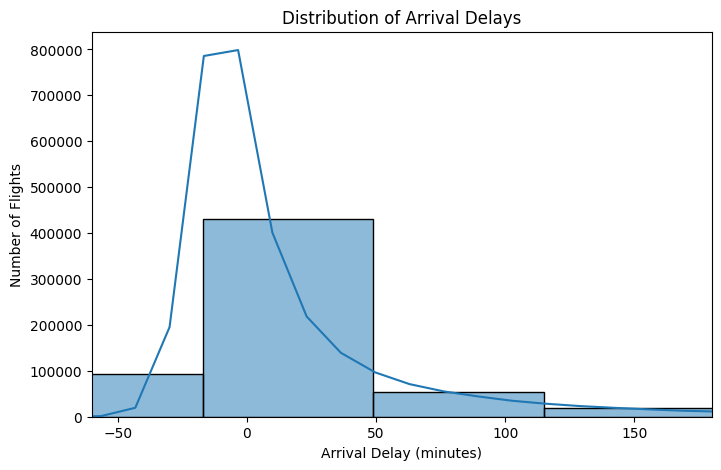

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["ArrDelay"], bins=40, kde=True)

plt.xlim(-60, 180)
plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")

plt.show()

Box plot

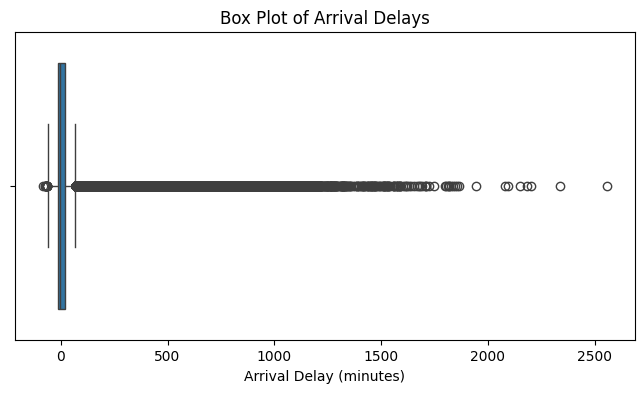

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["ArrDelay"])

plt.title("Box Plot of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")

plt.show()

Bar chart: flights by airline

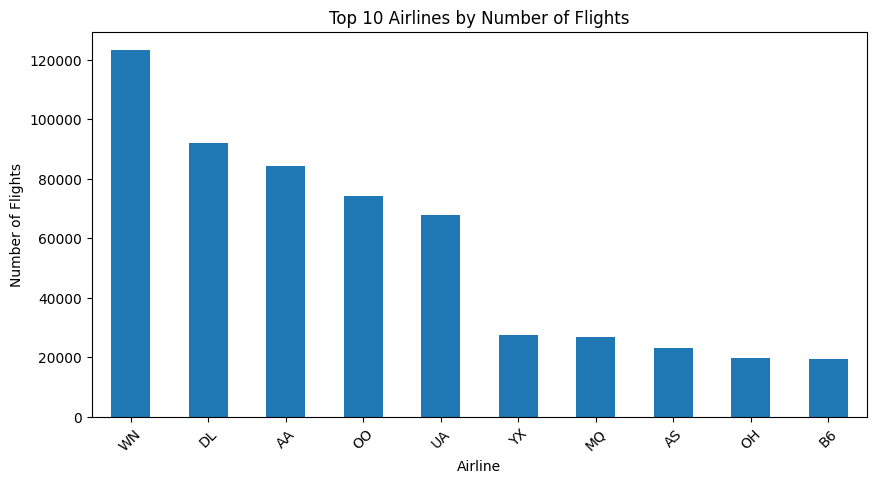

In [ ]:
airline_counts = df["Reporting_Airline"].value_counts().head(10)

plt.figure(figsize=(10, 5))

airline_counts.plot(kind="bar")

plt.title("Top 10 Airlines by Number of Flights")
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)

plt.show()

Pie chart: delay status

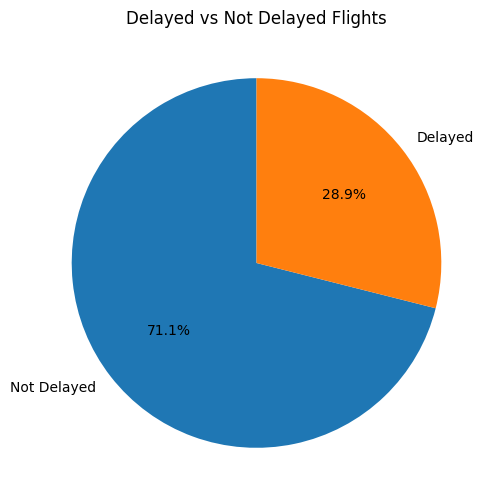

In [ ]:
delay_counts = df["Delay_Status"].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    delay_counts,
    labels=delay_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Delayed vs Not Delayed Flights")
plt.show()

Scatter plot: departure delay vs arrival delay

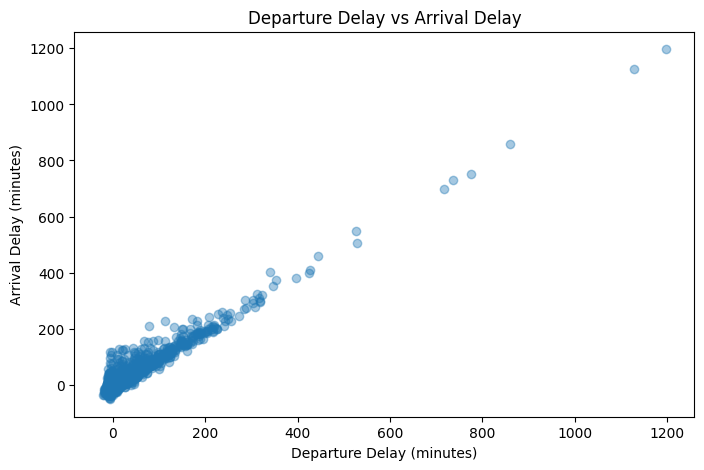

In [ ]:
sample_df = df.sample(
    n=min(3000, len(df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.scatter(
    sample_df["DepDelay"],
    sample_df["ArrDelay"],
    alpha=0.4
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")

plt.show()

Line chart: daily average arrival delays

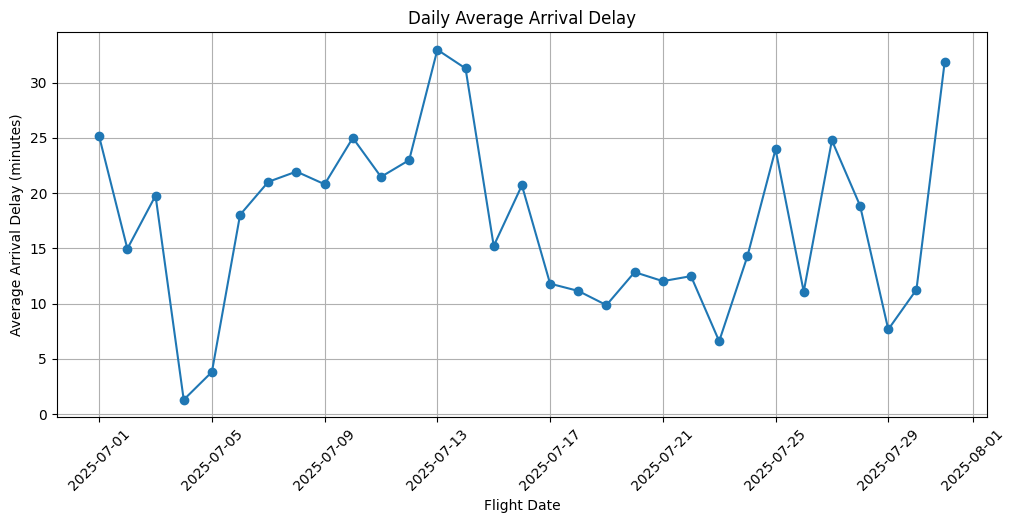

In [ ]:
daily_delay = (
    df.groupby("FlightDate")["ArrDelay"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_delay.index,
    daily_delay.values,
    marker="o"
)

plt.title("Daily Average Arrival Delay")
plt.xlabel("Flight Date")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

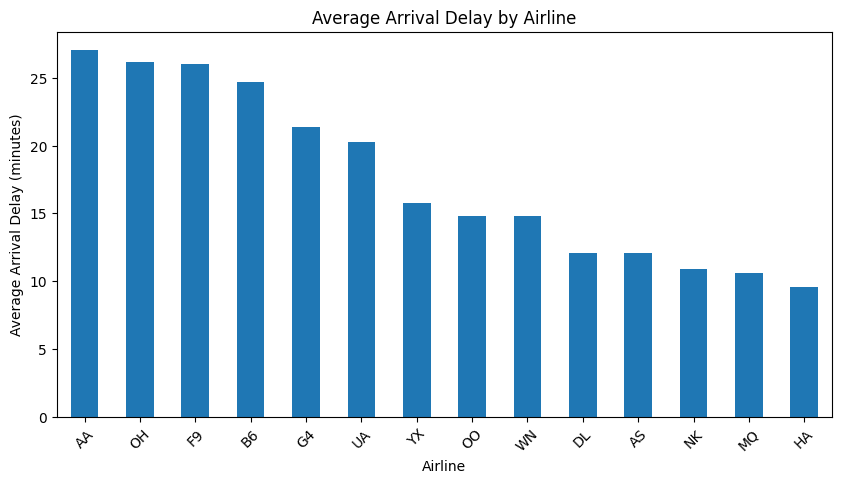

In [ ]:
airline_delay = (
    df.groupby("Reporting_Airline")["ArrDelay"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

airline_delay.plot(kind="bar")

plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=45)

plt.show()

In [ ]:
df.to_csv("cleaned_airline_flight_delays.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (611579, 9)


### Practical-3: To study probability distributions and implement various random sampling techniques on the dataset to understand sampling behavior and probability concepts using Python.

In [ ]:
df = pd.read_csv("cleaned_airline_flight_delays.csv")

delay = df["ArrDelay"].dropna()

print("Total flight records:", len(df))
print("Mean arrival delay:", delay.mean())
print("Standard deviation:", delay.std())

Total flight records: 611579
Mean arrival delay: 17.40118611005283
Standard deviation: 72.12376128415558


Normal distribution

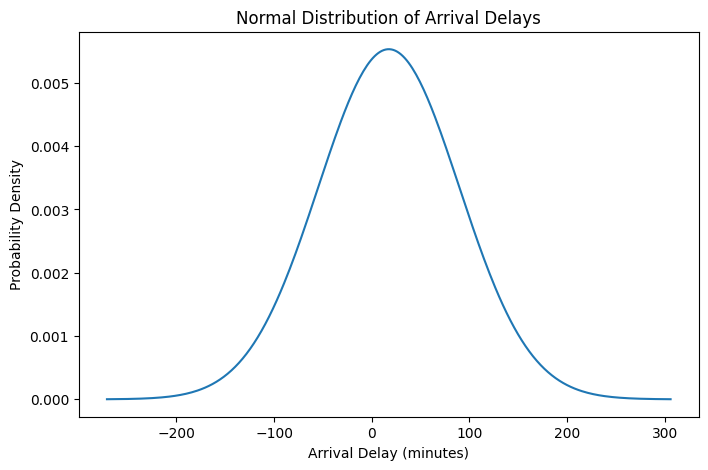

In [ ]:
mean_delay = delay.mean()
std_delay = delay.std()

x = np.linspace(
    mean_delay - 4 * std_delay,
    mean_delay + 4 * std_delay,
    300
)

y = stats.norm.pdf(x, mean_delay, std_delay)

plt.figure(figsize=(8, 5))

plt.plot(x, y)

plt.title("Normal Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Probability Density")

plt.show()

Uniform distribution

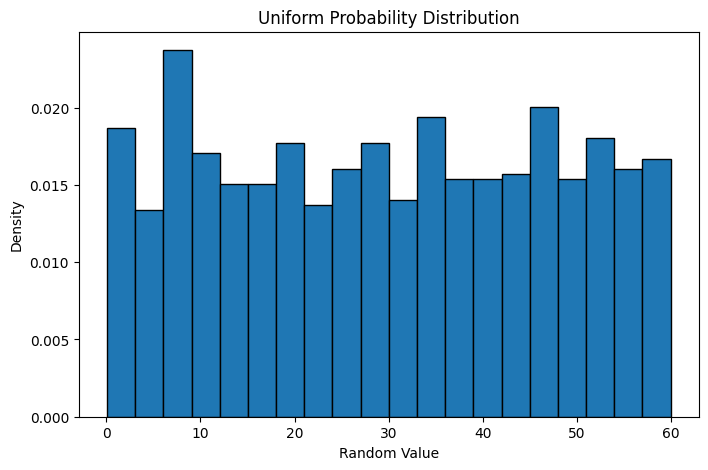

In [ ]:
uniform_data = np.random.default_rng(42).uniform(
    low=0,
    high=60,
    size=1000
)

plt.figure(figsize=(8, 5))

plt.hist(
    uniform_data,
    bins=20,
    density=True,
    edgecolor="black"
)

plt.title("Uniform Probability Distribution")
plt.xlabel("Random Value")
plt.ylabel("Density")

plt.show()

Binomial distribution

Probability of delay: 0.2893951558179728


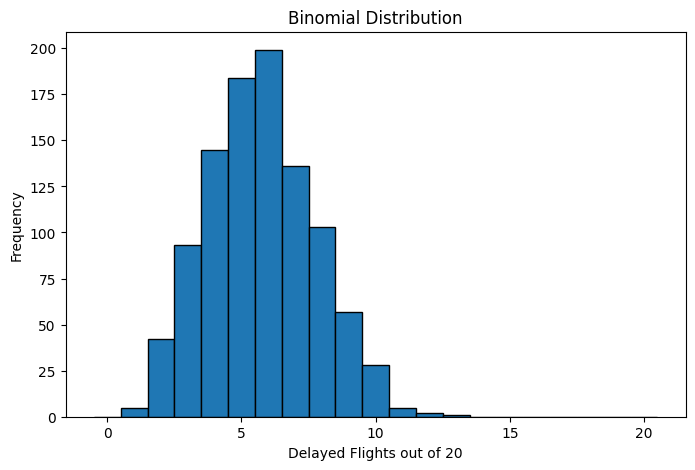

In [ ]:
p = (delay >= 15).mean()

print("Probability of delay:", p)

binomial_data = stats.binom.rvs(
    n=20,
    p=p,
    size=1000,
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.hist(
    binomial_data,
    bins=np.arange(-0.5, 21.5, 1),
    edgecolor="black"
)

plt.title("Binomial Distribution")
plt.xlabel("Delayed Flights out of 20")
plt.ylabel("Frequency")

plt.show()

Simple random sampling

In [ ]:
simple_sample = df.sample(
    n=min(100, len(df)),
    random_state=42
)

print("Simple Random Sample:")
display(simple_sample.head())

print("Sample size:", len(simple_sample))
print("Sample mean arrival delay:",
      simple_sample["ArrDelay"].mean())

Simple Random Sample:


,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,Cancelled,Distance,Delay_Status
462399,2025-07-03,YX,CMH,EWR,-7.0,-19.0,0.0,463.0,Not Delayed
360519,2025-07-12,WN,DEN,MSP,9.0,-1.0,0.0,680.0,Not Delayed
208011,2025-07-20,OO,DTW,LAN,-7.0,-7.0,0.0,74.0,Not Delayed
75002,2025-07-07,AA,PHX,RNO,-9.0,-5.0,0.0,601.0,Not Delayed
146904,2025-07-18,NK,DTW,LGA,-6.0,-7.0,0.0,502.0,Not Delayed


Sample size: 100
Sample mean arrival delay: 6.85


Systematic sampling

In [ ]:
k = 10

rng = np.random.default_rng(42)
start = rng.integers(0, min(k, len(df)))

systematic_sample = df.iloc[start::k]

print("Systematic Sample:")
display(systematic_sample.head())

print("Sample size:", len(systematic_sample))
print("Sample mean arrival delay:",
      systematic_sample["ArrDelay"].mean())

Systematic Sample:


,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,Cancelled,Distance,Delay_Status
0,2025-07-23,AA,MIA,CLT,-3.0,-5.0,0.0,650.0,Not Delayed
10,2025-07-02,AA,LGA,MIA,-3.0,45.0,0.0,1096.0,Delayed
20,2025-07-12,AA,LGA,MIA,421.0,396.0,0.0,1096.0,Delayed
30,2025-07-22,AA,LGA,MIA,-4.0,-25.0,0.0,1096.0,Not Delayed
40,2025-07-04,AA,LAX,DFW,-4.0,-1.0,0.0,1235.0,Not Delayed


Sample size: 61158
Sample mean arrival delay: 17.527502534419046


Stratified sampling

In [ ]:
df["Departure_Group"] = pd.cut(
    df["DepDelay"],
    bins=[-np.inf, 0, 15, 60, np.inf],
    labels=[
        "Early/On-time",
        "1-15 min",
        "16-60 min",
        "Over 60 min"
    ]
)

stratified_sample = (
    df.groupby(
        "Departure_Group",
        observed=True,
        group_keys=False
    )
    .sample(frac=0.10, random_state=42)
)

print("Stratified Sample:")
display(stratified_sample.head())

print("Sample size:", len(stratified_sample))

print("\nRecords from each group:")
print(stratified_sample["Departure_Group"].value_counts())

Stratified Sample:


,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,Cancelled,Distance,Delay_Status,Departure_Group
548484,2025-07-26,F9,SNA,PHX,-13.0,-17.0,0.0,338.0,Not Delayed,Early/On-time
423546,2025-07-22,WN,LAS,MKE,-1.0,-9.0,0.0,1524.0,Not Delayed,Early/On-time
65009,2025-07-18,AA,ORD,MCO,-4.0,-12.0,0.0,1005.0,Not Delayed,Early/On-time
27222,2025-07-20,AA,ORD,MCI,-5.0,-13.0,0.0,403.0,Not Delayed,Early/On-time
31556,2025-07-24,AA,FLL,CLT,-13.0,-30.0,0.0,632.0,Not Delayed,Early/On-time


Sample size: 61158

Records from each group:
Departure_Group
Early/On-time    33067
1-15 min         11092
16-60 min         9926
Over 60 min       7073
Name: count, dtype: int64


In [ ]:
print("Population Mean:",
      df["ArrDelay"].mean())

print("Simple Random Sample Mean:",
      simple_sample["ArrDelay"].mean())

print("Systematic Sample Mean:",
      systematic_sample["ArrDelay"].mean())

print("Stratified Sample Mean:",
      stratified_sample["ArrDelay"].mean())

Population Mean: 17.40118611005283
Simple Random Sample Mean: 6.85
Systematic Sample Mean: 17.527502534419046
Stratified Sample Mean: 17.274780077831192


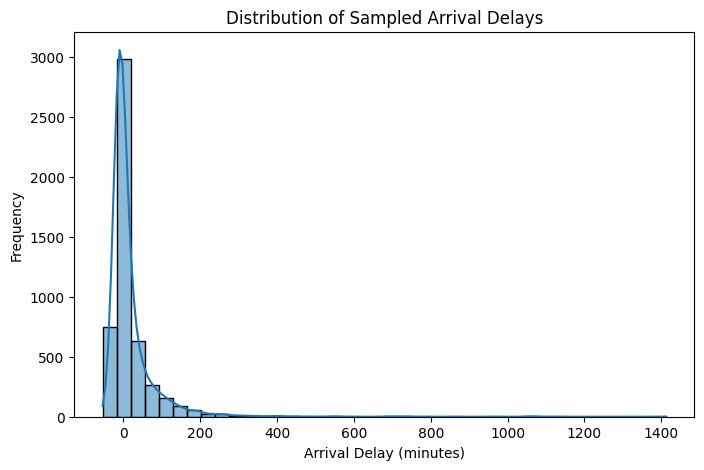

In [ ]:
plot_data = df["ArrDelay"].sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.histplot(plot_data, bins=40, kde=True)

plt.title("Distribution of Sampled Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Frequency")

plt.show()

In [ ]:
simple_sample.to_csv(
    "simple_random_sample.csv",
    index=False
)

systematic_sample.to_csv(
    "systematic_sample.csv",
    index=False
)

stratified_sample.to_csv(
    "stratified_sample.csv",
    index=False
)

print("All sampling datasets saved successfully!")

All sampling datasets saved successfully!


### Practical-4: To demonstrate the Central Limit Theorem through repeated sampling and estimate population parameters using sample statistics and point estimation techniques.

In [ ]:
df = pd.read_csv("cleaned_airline_flight_delays.csv")

population = df["ArrDelay"].dropna().to_numpy()

population_mean = np.mean(population)
population_std = np.std(population, ddof=0)

print("Population size:", len(population))
print("Population mean:", population_mean)
print("Population standard deviation:", population_std)

Population size: 611579
Population mean: 17.40118611005283
Population standard deviation: 72.12370231896602


Central Limit Theorem

In [ ]:
rng = np.random.default_rng(42)

sample_size = min(30, len(population))

sample = rng.choice(
    population,
    size=sample_size,
    replace=False
)

print("Sample size:", len(sample))
print("Sample mean:", np.mean(sample))
print("Population mean:", population_mean)

Sample size: 30
Sample mean: -4.9
Population mean: 17.40118611005283


In [ ]:
rng = np.random.default_rng(42)

sample_size = 30
number_of_samples = 1000

sample_means = []

for i in range(number_of_samples):
    sample = rng.choice(
        population,
        size=sample_size,
        replace=True
    )

    sample_means.append(np.mean(sample))

sample_means = np.array(sample_means)

print("Number of samples:", number_of_samples)
print("Mean of sample means:", sample_means.mean())
print("Population mean:", population_mean)

Number of samples: 1000
Mean of sample means: 17.46003333333333
Population mean: 17.40118611005283


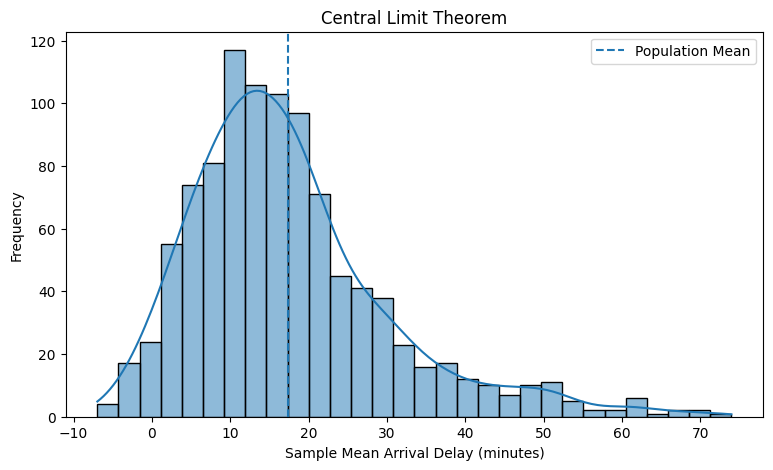

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(sample_means, bins=30, kde=True)

plt.axvline(
    population_mean,
    linestyle="--",
    label="Population Mean"
)

plt.title("Central Limit Theorem")
plt.xlabel("Sample Mean Arrival Delay (minutes)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

Compare different sample sizes

In [ ]:
rng = np.random.default_rng(42)

sample_sizes = [5, 15, 30, 50, 100]
results = []

for n in sample_sizes:
    means = []

    for i in range(1000):
        sample = rng.choice(
            population,
            size=n,
            replace=True
        )

        means.append(np.mean(sample))

    results.append({
        "Sample Size": n,
        "Mean of Sample Means": np.mean(means),
        "Standard Deviation of Sample Means": np.std(
            means, ddof=1
        )
    })

clt_results = pd.DataFrame(results)

display(clt_results)

,Sample Size,Mean of Sample Means,Standard Deviation of Sample Means
0,5,18.659200,34.459975
1,15,17.614867,17.728448
2,30,17.307867,12.831625
3,50,17.253680,10.289614
4,100,17.478400,7.265813


Plot the standard error for different sample sizes

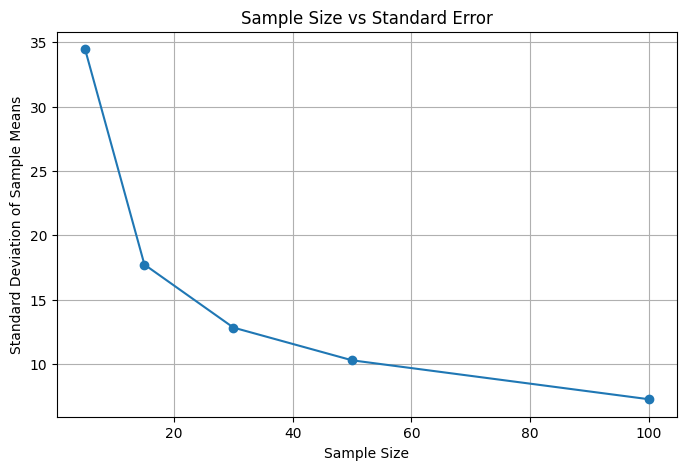

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    clt_results["Sample Size"],
    clt_results["Standard Deviation of Sample Means"],
    marker="o"
)

plt.title("Sample Size vs Standard Error")
plt.xlabel("Sample Size")
plt.ylabel("Standard Deviation of Sample Means")

plt.grid(True)
plt.show()

In [ ]:
for n in sample_sizes:
    standard_error = population_std / np.sqrt(n)

    print(
        "Sample Size:", n,
        "| Theoretical Standard Error:",
        round(standard_error, 3)
    )

Sample Size: 5 | Theoretical Standard Error: 32.255
Sample Size: 15 | Theoretical Standard Error: 18.622
Sample Size: 30 | Theoretical Standard Error: 13.168
Sample Size: 50 | Theoretical Standard Error: 10.2
Sample Size: 100 | Theoretical Standard Error: 7.212


Point estimation

In [ ]:
rng = np.random.default_rng(100)

sample = rng.choice(
    population,
    size=min(100, len(population)),
    replace=False
)

mean_estimate = np.mean(sample)
variance_estimate = np.var(sample, ddof=1)
std_estimate = np.std(sample, ddof=1)

print("Estimated Population Mean:", mean_estimate)
print("Estimated Population Variance:", variance_estimate)
print("Estimated Population Standard Deviation:", std_estimate)

Estimated Population Mean: 17.93
Estimated Population Variance: 2755.1566666666654
Estimated Population Standard Deviation: 52.48958626877016


Calculate a 95% confidence interval

In [ ]:
n = len(sample)

sample_mean = np.mean(sample)
sample_std = np.std(sample, ddof=1)

standard_error = sample_std / np.sqrt(n)

t_critical = stats.t.ppf(
    0.975,
    df=n - 1
)

lower = sample_mean - t_critical * standard_error
upper = sample_mean + t_critical * standard_error

print("Sample Mean:", sample_mean)
print("Standard Error:", standard_error)
print("95% Confidence Interval:")
print("Lower Limit:", lower)
print("Upper Limit:", upper)

Sample Mean: 17.93
Standard Error: 5.248958626877016
95% Confidence Interval:
Lower Limit: 7.514927314782886
Upper Limit: 28.34507268521711


In [ ]:
print("Actual Dataset Mean:", population_mean)
print("Estimated Sample Mean:", mean_estimate)

error = abs(population_mean - mean_estimate)

print("Absolute Estimation Error:", error)

Actual Dataset Mean: 17.40118611005283
Estimated Sample Mean: 17.93
Absolute Estimation Error: 0.5288138899471697


In [ ]:
clt_results.to_csv(
    "clt_results.csv",
    index=False
)

pd.DataFrame({
    "Sample Mean": sample_means
}).to_csv(
    "sample_means.csv",
    index=False
)

print("CLT results saved successfully!")

CLT results saved successfully!


### Practical-5

In [ ]:
delay = df["ArrDelay"].dropna()

sample = delay.sample(
    n=min(100, len(delay)),
    random_state=42
)

print("Sample size:", len(sample))
print("Sample mean:", sample.mean())
print("Sample standard deviation:", sample.std(ddof=1))

Sample size: 100
Sample mean: 6.85
Sample standard deviation: 37.09484839944461


In [ ]:
n = len(sample)
sample_mean = sample.mean()
sample_std = sample.std(ddof=1)

# Illustrative known population standard deviation
sigma = delay.std(ddof=0)

z_critical = stats.norm.ppf(0.975)

standard_error_z = sigma / np.sqrt(n)

z_lower = sample_mean - z_critical * standard_error_z
z_upper = sample_mean + z_critical * standard_error_z

print("Sample mean:", sample_mean)
print("Z critical value:", z_critical)
print("95% Z Confidence Interval:", (z_lower, z_upper))

Sample mean: 6.85
Z critical value: 1.959963984540054
95% Z Confidence Interval: (np.float64(-7.285985897678538), np.float64(20.98598589767854))


In [ ]:
t_critical = stats.t.ppf(0.975, df=n - 1)

standard_error_t = sample_std / np.sqrt(n)

t_lower = sample_mean - t_critical * standard_error_t
t_upper = sample_mean + t_critical * standard_error_t

print("Sample mean:", sample_mean)
print("t critical value:", t_critical)
print("95% t Confidence Interval:", (t_lower, t_upper))

Sample mean: 6.85
t critical value: 1.9842169515086827
95% t Confidence Interval: (np.float64(-0.5104227007822724), np.float64(14.21042270078227))


In [ ]:
mu0 = 10

z_statistic = (sample_mean - mu0) / (sigma / np.sqrt(n))

p_value_z = 2 * stats.norm.sf(abs(z_statistic))

print("Z Statistic:", z_statistic)
print("P-value:", p_value_z)

if p_value_z < 0.05:
    print("Reject H0: The mean arrival delay differs from 10 minutes.")
else:
    print("Fail to reject H0: Insufficient evidence that the mean differs from 10 minutes.")

Z Statistic: -0.43674962581244997
P-value: 0.6622929351321649
Fail to reject H0: Insufficient evidence that the mean differs from 10 minutes.


In [ ]:
t_statistic, p_value_t = stats.ttest_1samp(
    sample,
    popmean=10
)

print("T Statistic:", t_statistic)
print("P-value:", p_value_t)

if p_value_t < 0.05:
    print("Reject H0: The mean arrival delay differs from 10 minutes.")
else:
    print("Fail to reject H0: Insufficient evidence that the mean differs from 10 minutes.")

T Statistic: -0.8491745177336171
P-value: 0.3978329461105107
Fail to reject H0: Insufficient evidence that the mean differs from 10 minutes.


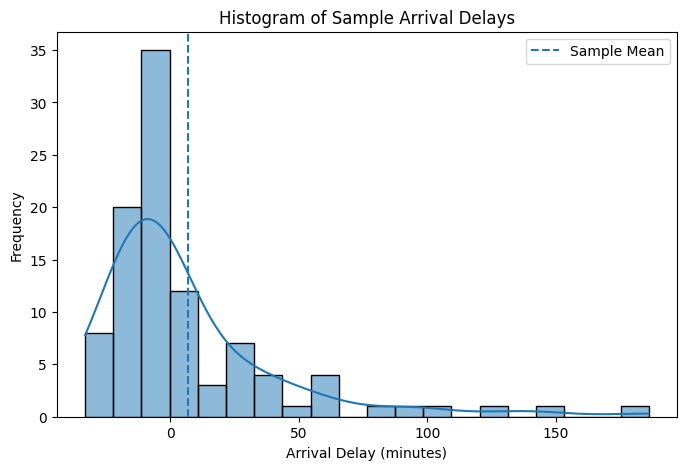

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(sample, bins=20, kde=True)

plt.axvline(
    sample_mean,
    linestyle="--",
    label="Sample Mean"
)

plt.title("Histogram of Sample Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

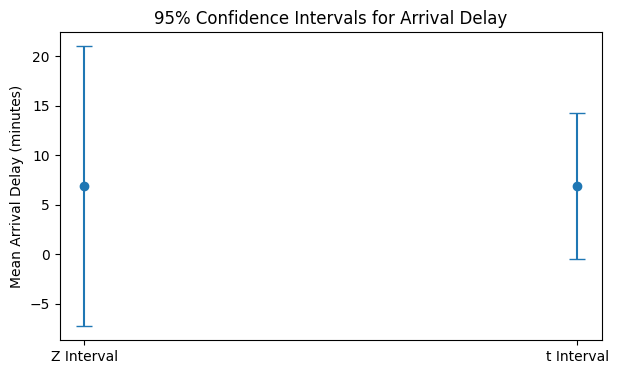

In [ ]:
plt.figure(figsize=(7, 4))

means = [sample_mean, sample_mean]

lower_errors = [
    sample_mean - z_lower,
    sample_mean - t_lower
]

upper_errors = [
    z_upper - sample_mean,
    t_upper - sample_mean
]

x_positions = [0, 1]

plt.errorbar(
    x_positions,
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=6
)

plt.xticks(x_positions, ["Z Interval", "t Interval"])
plt.ylabel("Mean Arrival Delay (minutes)")
plt.title("95% Confidence Intervals for Arrival Delay")

plt.show()

In [ ]:
results_p5 = pd.DataFrame({
    "Method": ["Z Confidence Interval", "t Confidence Interval"],
    "Sample Mean": [sample_mean, sample_mean],
    "Lower Limit": [z_lower, t_lower],
    "Upper Limit": [z_upper, t_upper]
})

display(results_p5)

,Method,Sample Mean,Lower Limit,Upper Limit
0,Z Confidence Interval,6.85,-7.285986,20.985986
1,t Confidence Interval,6.85,-0.510423,14.210423


### Practical 6

In [ ]:
df_anova = df[["Reporting_Airline", "ArrDelay"]].dropna()

top_airlines = (
    df_anova["Reporting_Airline"]
    .value_counts()
    .head(5)
    .index
)

df_anova = df_anova[
    df_anova["Reporting_Airline"].isin(top_airlines)
]

groups = [
    group["ArrDelay"].values
    for _, group in df_anova.groupby("Reporting_Airline")
]

print("Airlines selected:", list(top_airlines))

Airlines selected: ['WN', 'DL', 'AA', 'OO', 'UA']


In [ ]:
f_statistic, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one airline mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of different means.")

F-statistic: 612.9346320475385
P-value: 0.0
Reject H0: At least one airline mean differs.


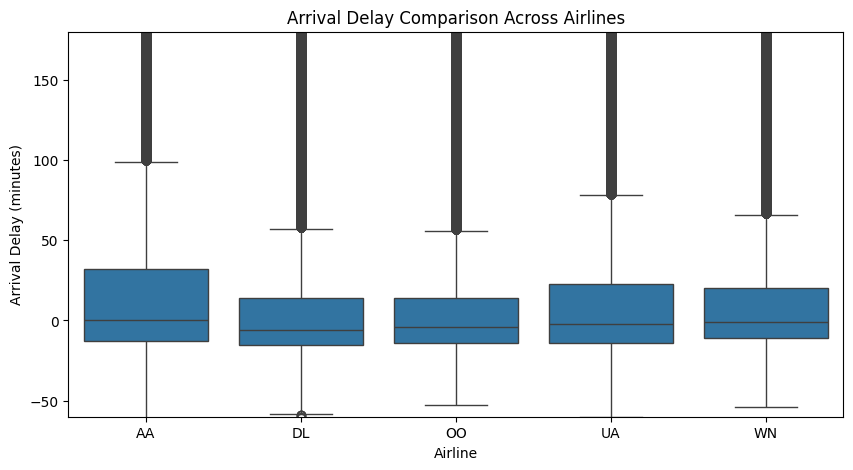

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_anova,
    x="Reporting_Airline",
    y="ArrDelay"
)

plt.ylim(-60, 180)
plt.title("Arrival Delay Comparison Across Airlines")
plt.xlabel("Airline")
plt.ylabel("Arrival Delay (minutes)")

plt.show()

In [ ]:
df_chi = df[["Reporting_Airline", "ArrDelay"]].dropna().copy()

top_airlines = (
    df_chi["Reporting_Airline"]
    .value_counts()
    .head(5)
    .index
)

df_chi = df_chi[
    df_chi["Reporting_Airline"].isin(top_airlines)
].copy()

df_chi["Delay_Status"] = np.where(
    df_chi["ArrDelay"] >= 15,
    "Delayed",
    "Not Delayed"
)

contingency_table = pd.crosstab(
    df_chi["Reporting_Airline"],
    df_chi["Delay_Status"]
)

display(contingency_table)

Delay_Status,Delayed,Not Delayed
Reporting_Airline,,
AA,29512,54721
DL,22916,69042
OO,18361,55995
UA,20682,47262
WN,35724,87502


In [ ]:
chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Airline and delay status are associated.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")

print("\nExpected frequencies:")
display(
    pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    ).round(2)
)

Chi-square statistic: 2975.672904003877
Degrees of freedom: 4
P-value: 0.0
Reject H0: Airline and delay status are associated.

Expected frequencies:


Delay_Status,Delayed,Not Delayed
Reporting_Airline,,
AA,24255.39,59977.61
DL,26479.85,65478.15
OO,21411.25,52944.75
UA,19564.87,48379.13
WN,35483.65,87742.35


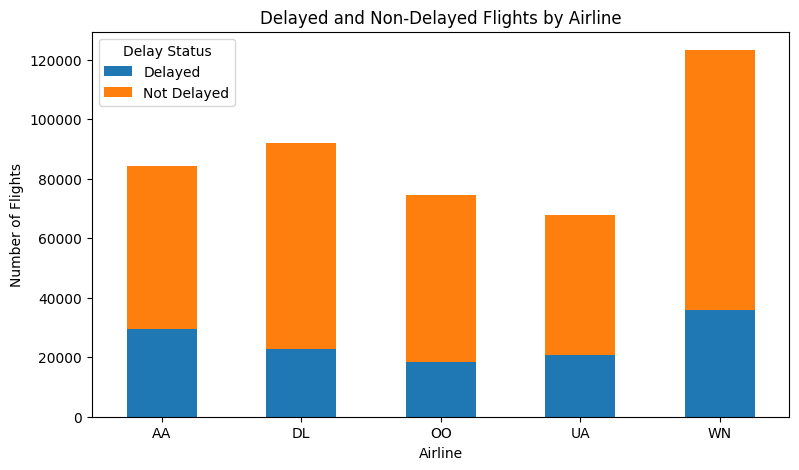

In [ ]:
contingency_table.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Delayed and Non-Delayed Flights by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.legend(title="Delay Status")

plt.show()

In [ ]:
covariance = df[["DepDelay", "ArrDelay"]].cov()

print("Covariance Matrix:")
display(covariance)

print("Covariance between departure and arrival delay:",
      covariance.loc["DepDelay", "ArrDelay"])

Covariance Matrix:


,DepDelay,ArrDelay
DepDelay,4911.564419,4935.189565
ArrDelay,4935.189565,5201.836942


Covariance between departure and arrival delay: 4935.189564819922


In [ ]:
pearson_corr, pearson_p = stats.pearsonr(
    df["DepDelay"],
    df["ArrDelay"]
)

print("Pearson Correlation:", pearson_corr)
print("P-value:", pearson_p)

Pearson Correlation: 0.9763725238374974
P-value: 0.0


In [ ]:
spearman_corr, spearman_p = stats.spearmanr(
    df["DepDelay"],
    df["ArrDelay"]
)

print("Spearman Correlation:", spearman_corr)
print("P-value:", spearman_p)

Spearman Correlation: 0.7797072813664101
P-value: 0.0


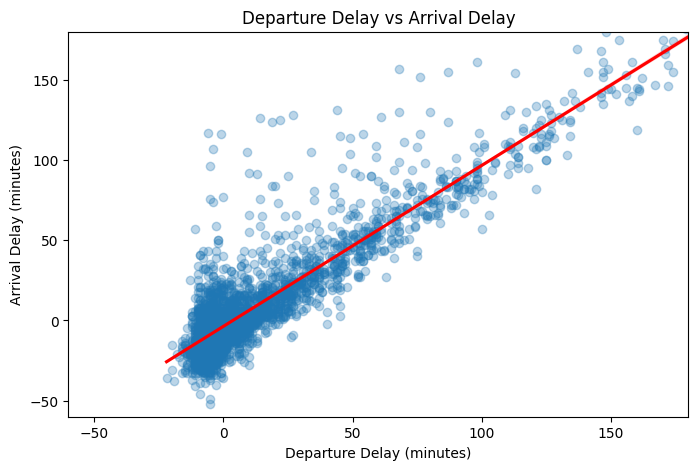

In [ ]:
sample_df = df.sample(
    n=min(3000, len(df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.regplot(
    data=sample_df,
    x="DepDelay",
    y="ArrDelay",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.xlim(-60, 180)
plt.ylim(-60, 180)
plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")

plt.show()

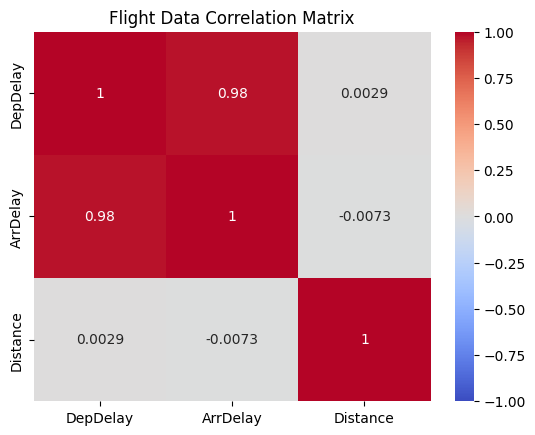

In [ ]:
correlation_matrix = df[
    ["DepDelay", "ArrDelay", "Distance"]
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Flight Data Correlation Matrix")
plt.show()

### Practical 7

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
ml_df = df[
    [
        "FlightDate",
        "Reporting_Airline",
        "DepDelay",
        "Distance",
        "ArrDelay"
    ]
].dropna().copy()

ml_df["FlightDate"] = pd.to_datetime(
    ml_df["FlightDate"],
    errors="coerce"
)

ml_df = ml_df.dropna(subset=["FlightDate"])

ml_df["Month"] = ml_df["FlightDate"].dt.month
ml_df["DayOfWeek"] = ml_df["FlightDate"].dt.dayofweek

print("Prepared dataset shape:", ml_df.shape)

display(ml_df.head())

Prepared dataset shape: (611579, 7)


,FlightDate,Reporting_Airline,DepDelay,Distance,ArrDelay,Month,DayOfWeek
0,2025-07-23,AA,-3.0,650.0,-5.0,7,2
1,2025-07-24,AA,85.0,650.0,74.0,7,3
2,2025-07-25,AA,-4.0,650.0,-18.0,7,4
3,2025-07-26,AA,-5.0,650.0,10.0,7,5
4,2025-07-27,AA,4.0,650.0,-13.0,7,6


In [ ]:
X = ml_df[
    [
        "DepDelay",
        "Distance",
        "Month",
        "DayOfWeek",
        "Reporting_Airline"
    ]
]

y = ml_df["ArrDelay"]

print("Input features:", X.columns.tolist())
print("Target variable: ArrDelay")

Input features: ['DepDelay', 'Distance', 'Month', 'DayOfWeek', 'Reporting_Airline']
Target variable: ArrDelay


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 489263
Testing records: 122316


In [ ]:
numeric_features = [
    "DepDelay",
    "Distance",
    "Month",
    "DayOfWeek"
]

categorical_features = ["Reporting_Airline"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "airline",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Models ready:")
print(list(models.keys()))

Models ready:
['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Decision Tree', 'Random Forest']


In [ ]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print(name, "completed")

Linear Regression completed
Ridge Regression completed
Lasso Regression completed
Decision Tree completed
Random Forest completed


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]

print("Best model based on RMSE:", best_model_name)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,10.1863,240.2403,15.4997,0.9550
1,Ridge Regression,10.1868,240.2426,15.4998,0.9550
4,Random Forest,10.2401,241.3836,15.5365,0.9548
2,Lasso Regression,10.2263,241.4064,15.5373,0.9548
3,Decision Tree,10.3400,248.7472,15.7717,0.9534


Best model based on RMSE: Linear Regression


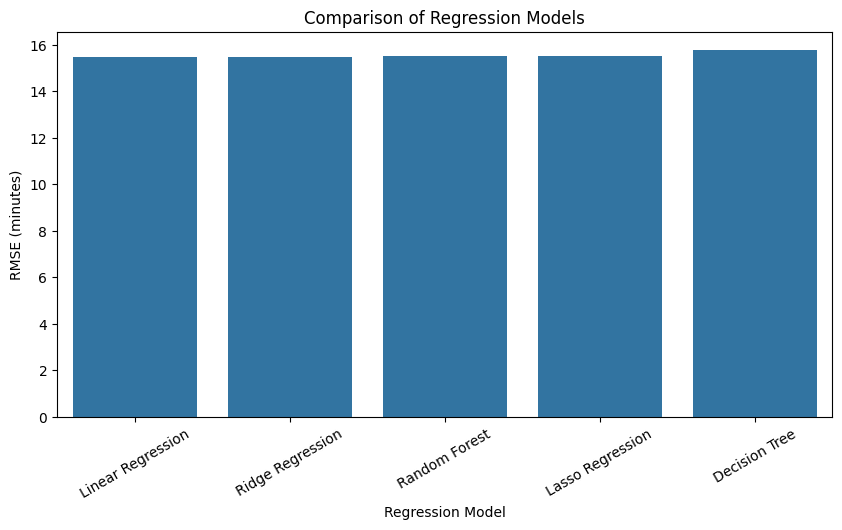

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("RMSE (minutes)")
plt.xticks(rotation=30)

plt.show()

In [ ]:
best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Arrival Delay": y_test.to_numpy(),
    "Predicted Arrival Delay": predictions
})

display(comparison.head(10))

,Actual Arrival Delay,Predicted Arrival Delay
0,-19.0,-10.440565
1,-1.0,3.394090
2,-7.0,-8.904870
3,-5.0,-13.082287
4,-7.0,-11.431745
5,-29.0,-13.602475
6,6.0,2.573905
7,-17.0,-12.556904
8,-7.0,-3.229207
9,3.0,7.393237


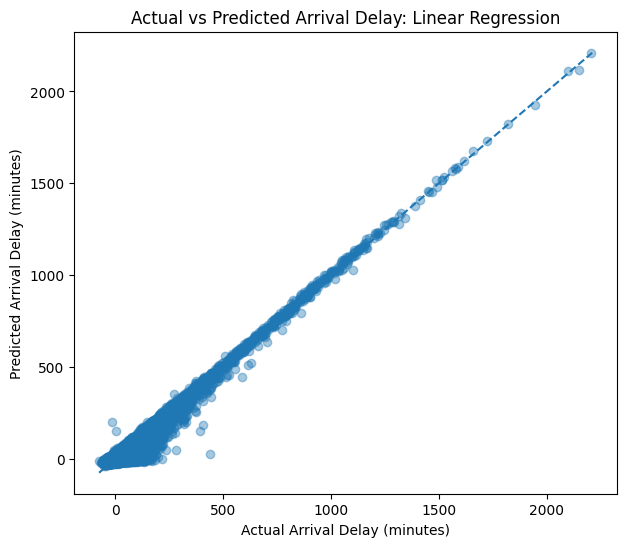

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.4
)

min_value = min(y_test.min(), predictions.min())
max_value = max(y_test.max(), predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Arrival Delay: {best_model_name}")
plt.xlabel("Actual Arrival Delay (minutes)")
plt.ylabel("Predicted Arrival Delay (minutes)")

plt.show()

In [ ]:
import joblib

results_df.to_csv(
    "regression_model_comparison.csv",
    index=False
)

joblib.dump(
    best_model,
    "best_flight_delay_regression_model.pkl"
)

print("Model comparison saved.")
print("Best model saved successfully.")

Model comparison saved.
Best model saved successfully.


### Practical 8 — To build and analyze a multiple linear regression model using statistical programming tools by considering multiple independent variables, and to interpret the effect of each predictor on the dependent variable.


In [ ]:
df = pd.read_csv("cleaned_airline_flight_delays.csv")

In [ ]:
df["FlightDate"] = pd.to_datetime(df["FlightDate"])
df["Month"] = df["FlightDate"].dt.month
df["DayOfWeek"] = df["FlightDate"].dt.dayofweek

X = df[["DepDelay", "Distance", "Month", "DayOfWeek"]]
y = df["ArrDelay"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [ 1.00496979 -0.00122258  0.          0.04023342]
Intercept: -3.1801815192262275


In [ ]:
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MSE: 242.4390468538964
RMSE: 15.570454291827724
R2 Score: 0.9546229428755898


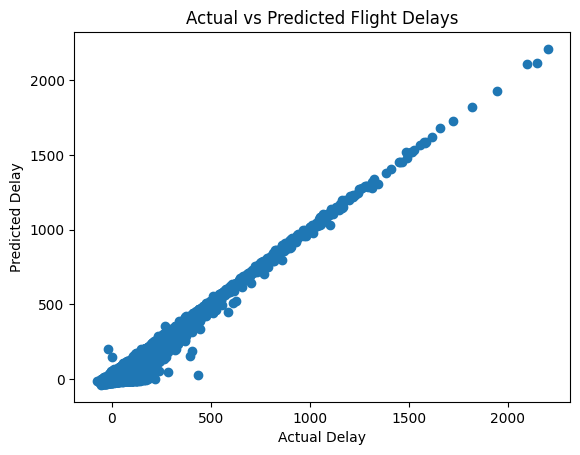

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Delay")
plt.ylabel("Predicted Delay")
plt.title("Actual vs Predicted Flight Delays")
plt.show()